<a href="https://colab.research.google.com/github/romandudarets/Data-Analysis-University/blob/main/%D0%9B%D1%807_%D0%94%D1%83%D0%B4%D0%B0%D1%80%D0%B5%D1%86%D1%8C_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

sns.set(style="whitegrid")

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [3]:
from google.colab import files

files.upload()
df = pd.read_csv("data.csv")
df.head()

Saving data.csv to data.csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [4]:
import kagglehub
import os

path = kagglehub.dataset_download("unmoved/cure-the-princess")
df = pd.read_csv(os.path.join(path, "data.csv"))
df.head()

100%|██████████| 49.2k/49.2k [00:00<00:00, 2.62MB/s]

Extracting files...


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [5]:
print("Розмір датасету (рядки, стовпці):", df.shape)
display(df.head())
print("\nІнформація про структуру даних:")
df.info()

Розмір датасету (рядки, стовпці): (2338, 14)


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0



Інформація про структуру даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [6]:
print("Кількість пропущених значень по стовпцях:\n", df.isnull().sum())
print("\nКількість повних дублікатів:", df.duplicated().sum())

Кількість пропущених значень по стовпцях:
 Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість повних дублікатів: 0


In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


**Висновок за первинним оглядом:**  
У ході первинного огляду датасету data.csv перевірено розміри таблиці, типи ознак, наявність пропусків та дублікатів. Усі ознаки магічних інгредієнтів та цільова змінна Cured мають числовий формат, а дані готові до подальшого аналізу після перевірки на пропуски й дублікати.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [8]:
X = df.drop(columns=["Cured"])
y = df["Cured"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (1870, 13) | X_test: (468, 13)
y_train: (1870,) | y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [9]:
print("Кількість спостережень кожного класу в y_train:")
print(y_train.value_counts())
print("\nЧастка класів (%):")
print(y_train.value_counts(normalize=True) * 100)

Кількість спостережень кожного класу в y_train:
Cured
0    941
1    929
Name: count, dtype: int64

Частка класів (%):
Cured
0    50.320856
1    49.679144
Name: proportion, dtype: float64


/tmp/ipykernel_398/1816974064.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, palette="pastel")


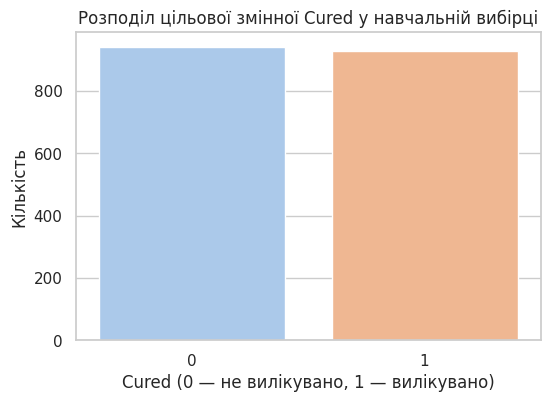

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train, palette="pastel")
plt.title("Розподіл цільової змінної Cured у навчальній вибірці")
plt.xlabel("Cured (0 — не вилікувано, 1 — вилікувано)")
plt.ylabel("Кількість")
plt.show()

**Висновок:**  
Розподіл класів у y_train показує співвідношення між вилікуваними (1) та невилікуваними (0) випадками. Якщо класи збалансовані або мають помірний перекос, Accuracy дає базове уявлення, але при дисбалансі одна метрика Accuracy може маскувати гіршу якість розпізнавання меншого класу, тому важливо також дивитися на precision, recall та F1-score.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

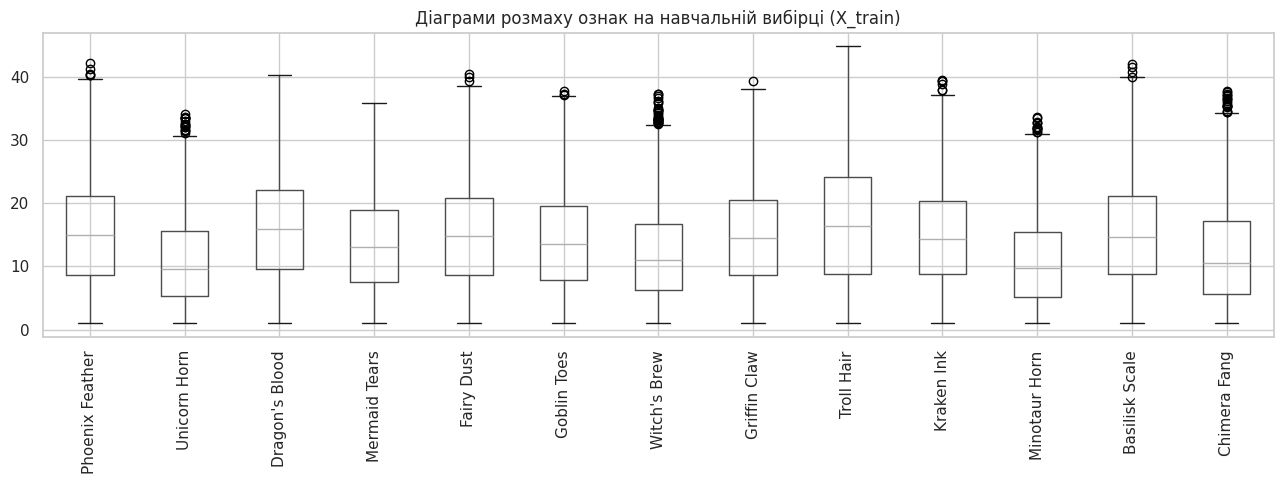

In [11]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title("Діаграми розмаху ознак на навчальній вибірці (X_train)")
plt.tight_layout()
plt.show()

In [12]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers_count = ((X_train < lower_bound) | (X_train > upper_bound)).sum().sort_values(ascending=False)
print("Кількість потенційних викидів за правилом 1.5 * IQR на X_train:")
print(outliers_count)

Кількість потенційних викидів за правилом 1.5 * IQR на X_train:
Witch's Brew       31
Chimera Fang       18
Unicorn Horn       17
Minotaur Horn      13
Kraken Ink          6
Phoenix Feather     5
Basilisk Scale      4
Fairy Dust          3
Goblin Toes         3
Griffin Claw        1
Dragon's Blood      0
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
Найбільша кількість потенційних викидів за правилом 1.5 * IQR спостерігається у верхніх рядках таблиці вище. Видаляти всі рядки з формальними викидами без перевірки не варто, оскільки для невеликого датасету це призведе до втрати частини спостережень, а деякі екстремальні значення можуть нести корисну інформацію про вплив інгредієнтів.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

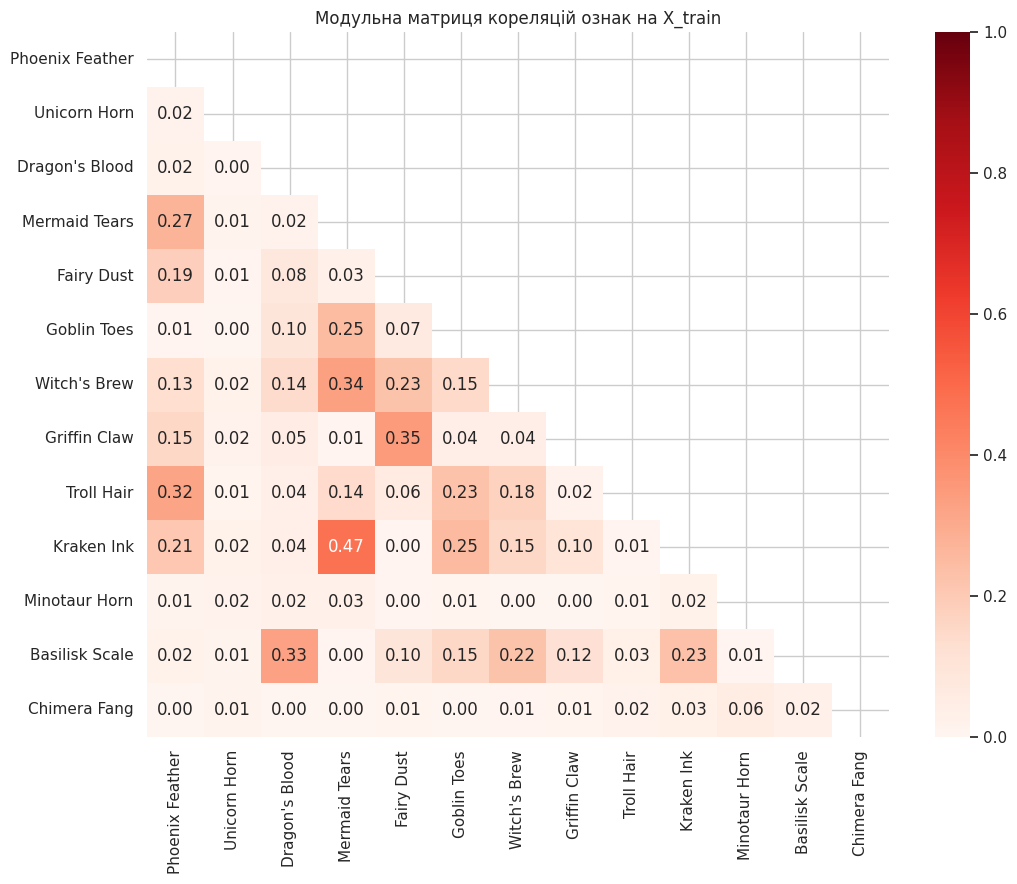

In [13]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1)
plt.title("Модульна матриця кореляцій ознак на X_train")
plt.tight_layout()
plt.show()

In [14]:
corr_with_target = (
    pd.concat([X_train, y_train], axis=1)
    .corr()["Cured"]
    .drop("Cured")
    .sort_values(key=abs, ascending=False)
)
print("Кореляція ознак із Cured на навчальній вибірці (за спаданням |r|):")
print(corr_with_target)

Кореляція ознак із Cured на навчальній вибірці (за спаданням |r|):
Troll Hair         0.504026
Witch's Brew       0.237690
Basilisk Scale    -0.055086
Goblin Toes        0.049919
Kraken Ink        -0.037099
Phoenix Feather    0.024068
Unicorn Horn      -0.021990
Griffin Claw      -0.020528
Chimera Fang       0.018197
Dragon's Blood     0.016741
Minotaur Horn      0.008981
Mermaid Tears      0.001563
Fairy Dust         0.001404
Name: Cured, dtype: float64


**Висновок про кореляції:**  
Теплова карта допомагає виявити пари найбільш взаємопов'язаних ознак інгредієнтів на навчальній вибірці, а список кореляцій із Cured показує ознаки з найсильнішим позитивним або негативним лінійним зв'язком із цільовою змінною.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [16]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print("Accuracy (LogisticRegression):", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

Accuracy (LogisticRegression): 0.8526

Classification Report:
              precision    recall  f1-score   support

           0     0.8615    0.8432    0.8522       236
           1     0.8439    0.8621    0.8529       232

    accuracy                         0.8526       468
   macro avg     0.8527    0.8526    0.8526       468
weighted avg     0.8528    0.8526    0.8526       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

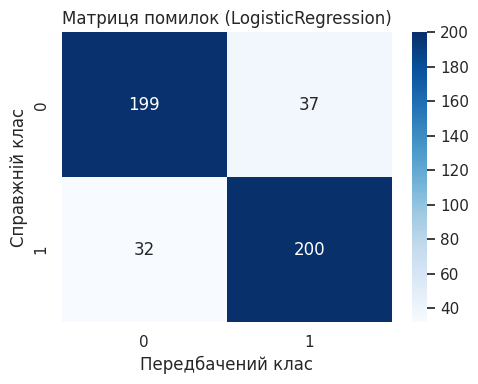

In [17]:
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues")
plt.title("Матриця помилок (LogisticRegression)")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.tight_layout()
plt.show()

In [18]:
comparison_10 = pd.DataFrame({
    "Справжній клас (y_test)": y_test.values,
    "Передбачений клас (y_pred)": y_pred,
}, index=y_test.index)

display(comparison_10.sample(10, random_state=42))

,Справжній клас (y_test),Передбачений клас (y_pred)
1318,0,0
244,0,0
996,1,1
930,0,0
839,0,0
1251,1,1
335,1,1
1670,0,0
1118,0,0
2175,1,1


**Висновок щодо якості логістичної регресії:**  
Матриця помилок показує розподіл правильних прогнозів (TN, TP) та помилок (FP, FN). Однієї метрики Accuracy часто недостатньо для повної оцінки, оскільки вона не показує, чи не пропускає модель позитивні випадки (FN) або чи не хибно спрацьовує (FP).

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [19]:
param_grid = {
    "C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "solver": ["lbfgs", "liblinear"],
    "max_iter": [200, 500, 1000],
}

param_dist = {
    "C": np.logspace(-2, 2, 25),
    "solver": ["lbfgs", "liblinear"],
    "max_iter": [200, 500, 1000, 1500],
}

In [20]:
grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
)
grid.fit(X_train_scaled, y_train)

print("GridSearchCV найкращі параметри:", grid.best_params_)
print("GridSearchCV найкращий CV Accuracy:", round(grid.best_score_, 4))

GridSearchCV найкращі параметри: {'C': 10.0, 'max_iter': 200, 'solver': 'lbfgs'}
GridSearchCV найкращий CV Accuracy: 0.8749


In [21]:
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
)
random_search.fit(X_train_scaled, y_train)

print("RandomizedSearchCV найкращі параметри:", random_search.best_params_)
print("RandomizedSearchCV найкращий CV Accuracy:", round(random_search.best_score_, 4))

RandomizedSearchCV найкращі параметри: {'solver': 'lbfgs', 'max_iter': 1500, 'C': np.float64(14.67799267622069)}
RandomizedSearchCV найкращий CV Accuracy: 0.8749


In [22]:
best_lr = grid.best_estimator_ if grid.best_score_ >= random_search.best_score_ else random_search.best_estimator_
y_pred_tuned = best_lr.predict(X_test_scaled)

print("Accuracy після підбору гіперпараметрів:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("\nClassification Report (tuned LogisticRegression):")
print(classification_report(y_test, y_pred_tuned, digits=4))

Accuracy після підбору гіперпараметрів: 0.8504

Classification Report (tuned LogisticRegression):
              precision    recall  f1-score   support

           0     0.8578    0.8432    0.8504       236
           1     0.8432    0.8578    0.8504       232

    accuracy                         0.8504       468
   macro avg     0.8505    0.8505    0.8504       468
weighted avg     0.8506    0.8504    0.8504       468



**Висновок про підбір параметрів:**  
GridSearchCV та RandomizedSearchCV підібрали оптимальні значення C, solver і max_iter на крос-валідації (cv=3) за метрикою accuracy. Залежно від даних підбір параметрів або підвищує/стабілізує узагальнювальну здатність моделі, або підтверджує, що базова конфігурація вже близька до оптимуму.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [23]:
svc_model = SVC(kernel="rbf", random_state=42)
svc_model.fit(X_train_scaled, y_train)
y_pred_svc = svc_model.predict(X_test_scaled)

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_scaled, y_train)
y_pred_tree = tree_model.predict(X_test_scaled)

comparison_models = pd.DataFrame([
    {
        "Модель": "LogisticRegression (tuned)",
        "Accuracy": accuracy_score(y_test, y_pred_tuned),
        "F1-score": f1_score(y_test, y_pred_tuned),
    },
    {
        "Модель": "SVC",
        "Accuracy": accuracy_score(y_test, y_pred_svc),
        "F1-score": f1_score(y_test, y_pred_svc),
    },
    {
        "Модель": "DecisionTreeClassifier",
        "Accuracy": accuracy_score(y_test, y_pred_tree),
        "F1-score": f1_score(y_test, y_pred_tree),
    },
]).sort_values(by="F1-score", ascending=False).reset_index(drop=True)

display(comparison_models)

,Модель,Accuracy,F1-score
0,SVC,0.933761,0.932755
1,LogisticRegression (tuned),0.850427,0.850427
2,DecisionTreeClassifier,0.824786,0.824034


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
Особливості даних: під час первинного аналізу визначено розмір вибірки, типи числових ознак і цільової змінної Cured, а також перевірено відсутність пропусків і дублікатів.

Викиди та кореляції на train: аналіз на навчальній вибірці виявив потенційні викиди за правилом 1.5 * IQR (які не видалялися без перевірки), а також взаємозв'язки між ознаками та з Cured.

Базова логістична регресія: модель показала певні значення Accuracy, precision, recall та F1-score на стандартизованій тестовій вибірці; матриця помилок дозволила оцінити співвідношення FP і FN.

Підбір гіперпараметрів: пошук через GridSearchCV та RandomizedSearchCV (cv=3) дозволив перевірити різні комбінації C, solver та max_iter і оцінити вплив на якість прогнозів.

Найкраща модель: порівняння Logistic Regression, SVC та DecisionTreeClassifier за Accuracy і F1-score на однаковій тестовій вибірці показує, яка модель найкраще узагальнює залежності у даних (обираємо модель із вищими F1-score та Accuracy у таблиці вище).

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.